# The Portal Fare Prophecy — Complete Pipeline
### EDA → Cleaning → Features → Leak-free CV → GBM Ensemble → Residual Diagnostics → Submission
**Code Sangam 2026 · Logical Rhythm · Realm I (Tabular Regression, target = `total_amount`)**

This notebook is the full A-to-Z solution: audit the data, clean it with a fully logged rule set, explore the signal, engineer features, validate without leakage, train a LightGBM / CatBoost / XGBoost ensemble, diagnose residuals and write `submission.csv`.

**Guiding principles**
1. Every cleaning decision is **justified, counted and logged** (nothing is silently dropped).
2. Rows are only ever **removed from train**; the test set is never filtered (we must predict every test id).
3. All statistics used for imputation / clipping are **fitted on train only** and re-applied to test.
4. The run is **deterministic** (fixed seeds).

**Contents**
1. Setup & reproducibility
2. Data overview
3. Target analysis
4. Data-quality audit
5. Cleaning & imputation (logged)
6. Temporal analysis
7. Distance / duration / speed analysis
8. Categorical analysis
8b. Refund (negative-fare) regime & fare additivity
9. Spatial (zone) analysis
10. Correlation analysis
11. Train vs test distribution check (adversarial validation)
12. Key findings & modelling plan
13. Feature engineering (incl. leak-free target encoding)
14. Cross-validation framework
15. Models: LightGBM / CatBoost / XGBoost
16. Ensemble (weighted blend)
17. Residual error diagnostics
18. Submission file
19. Reproducibility log

## 1. Setup & reproducibility

In [2]:
import os, glob, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); os.environ["PYTHONHASHSEED"] = str(SEED)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.labelsize": 10, "figure.figsize": (8, 4.5)})

TARGET = "total_amount"
SURCHARGES = ["extra", "tip_amount", "tolls_amount", "improvement_surcharge",
              "congestion_surcharge", "Airport_fee"]
NON_TIP = [c for c in SURCHARGES if c != "tip_amount"]

# --- Local Automatic Path Resolver ---
if os.path.exists("./data/train.csv"):
    DATA_DIR = "./data/"
elif os.path.exists("./train.csv"):
    DATA_DIR = "./"
else:
    DATA_DIR = os.path.dirname(glob.glob("/kaggle/input/**/train.csv", recursive=True)[0]) + "/"

print("Data directory:", DATA_DIR)

Data directory: ./


## 2. Data overview

In [3]:
train_raw = pd.read_csv(DATA_DIR + "train.csv")
test_raw  = pd.read_csv(DATA_DIR + "test.csv")
print(f"train: {train_raw.shape} | test: {test_raw.shape}")
print("Columns only in train:", sorted(set(train_raw.columns) - set(test_raw.columns)))
print("Columns only in test :", sorted(set(test_raw.columns) - set(train_raw.columns)))
display(train_raw.head())

train: (8000, 17) | test: (2000, 17)
Columns only in train: ['total_amount']
Columns only in test : ['id']


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,extra,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,1,2023-06-29 19:30:24,2023-06-29 18:24:35,1.0,1.45,1.0,N,58,82,Credit Card,2.5,8.105869,0.0,1.0,25.68,2.5,0.0
1,1,2023-06-28 16:52:43,2023-06-28 17:20:05,6.0,0.98,1.0,N,253,153,Cash,2.5,0.570916,0.0,1.0,15.10,2.5,0.0
2,0,2023-06-30 06:03:32,2023-06-30 05:53:56,1.0,0.40,1.0,N,85,264,Credit Card,2.5,4.616720,0.0,1.0,10.40,2.5,0.0
3,1,2023-06-30 14:09:29,2023-06-30 13:07:32,1.0,0.85,1.0,N,2,139,Credit Card,0.0,3.380739,0.0,1.0,12.32,2.5,0.0
4,1,2023-06-30 00:35:04,2023-06-29 23:44:36,NaN,4.59,NaN,NaN,12,99,Wallet,0.0,1.534365,0.0,1.0,27.56,NaN,NaN


,dtype,missing,missing_%,n_unique
VendorID,int64,0,0.00,2
tpep_pickup_datetime,object,0,0.00,7825
tpep_dropoff_datetime,object,0,0.00,7839
passenger_count,float64,290,3.62,7
trip_distance,float64,0,0.00,1371
RatecodeID,float64,290,3.62,6
store_and_fwd_flag,object,290,3.62,2
PULocationID,int64,0,0.00,264
DOLocationID,int64,0,0.00,264
payment_type,object,0,0.00,5


Duplicate rows (train): 0


,count,mean,std,min,25%,50%,75%,max
VendorID,8000.0,0.732,0.443,0.000,0.000,1.000,1.000,1.000
passenger_count,7710.0,1.359,0.888,0.000,1.000,1.000,1.000,6.000
trip_distance,8000.0,3.717,4.934,0.000,1.070,1.830,3.690,58.200
RatecodeID,7710.0,1.465,6.110,1.000,1.000,1.000,1.000,99.000
PULocationID,8000.0,132.428,75.893,1.000,67.000,132.000,198.000,264.000
DOLocationID,8000.0,132.990,76.177,1.000,68.000,134.000,200.000,264.000
extra,8000.0,1.930,1.942,-7.500,0.000,1.000,2.500,11.750
tip_amount,8000.0,6.115,4.460,0.001,3.498,5.222,7.455,84.033
tolls_amount,8000.0,0.685,2.490,-26.550,0.000,0.000,0.000,32.050
improvement_surcharge,8000.0,0.980,0.197,-1.000,1.000,1.000,1.000,1.000


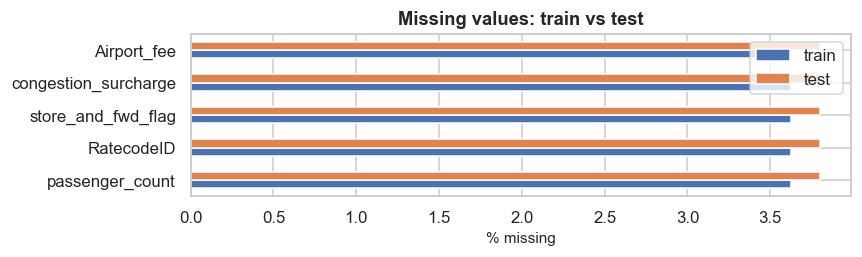

In [4]:
summary = pd.DataFrame({
    "dtype": train_raw.dtypes.astype(str),
    "missing": train_raw.isna().sum(),
    "missing_%": (train_raw.isna().mean() * 100).round(2),
    "n_unique": train_raw.nunique(),
})
display(summary)
print("Duplicate rows (train):", train_raw.duplicated().sum())
display(train_raw.describe().T.round(3))

miss = pd.concat([train_raw.isna().mean().rename("train"),
                  test_raw.isna().mean().rename("test")], axis=1) * 100
miss = miss[(miss > 0).any(axis=1)]
if len(miss):
    ax = miss.plot(kind="barh", figsize=(8, max(2.5, 0.5 * len(miss))))
    ax.set_xlabel("% missing"); ax.set_title("Missing values: train vs test")
    plt.tight_layout(); plt.show()
else:
    print("No missing values in either file.")

## 3. Target analysis
Fares are bounded below by zero and typically right-skewed, with a long tail of airport / long-distance trips. We inspect the distribution on both raw and log scales and check normality, because the metric (RMSE) is dominated by large fares.

count    8000.00
mean       29.90
std        26.04
min      -129.30
25%        16.32
50%        21.42
75%        32.00
max       485.10

Skewness: 3.18 | Excess kurtosis: 25.15


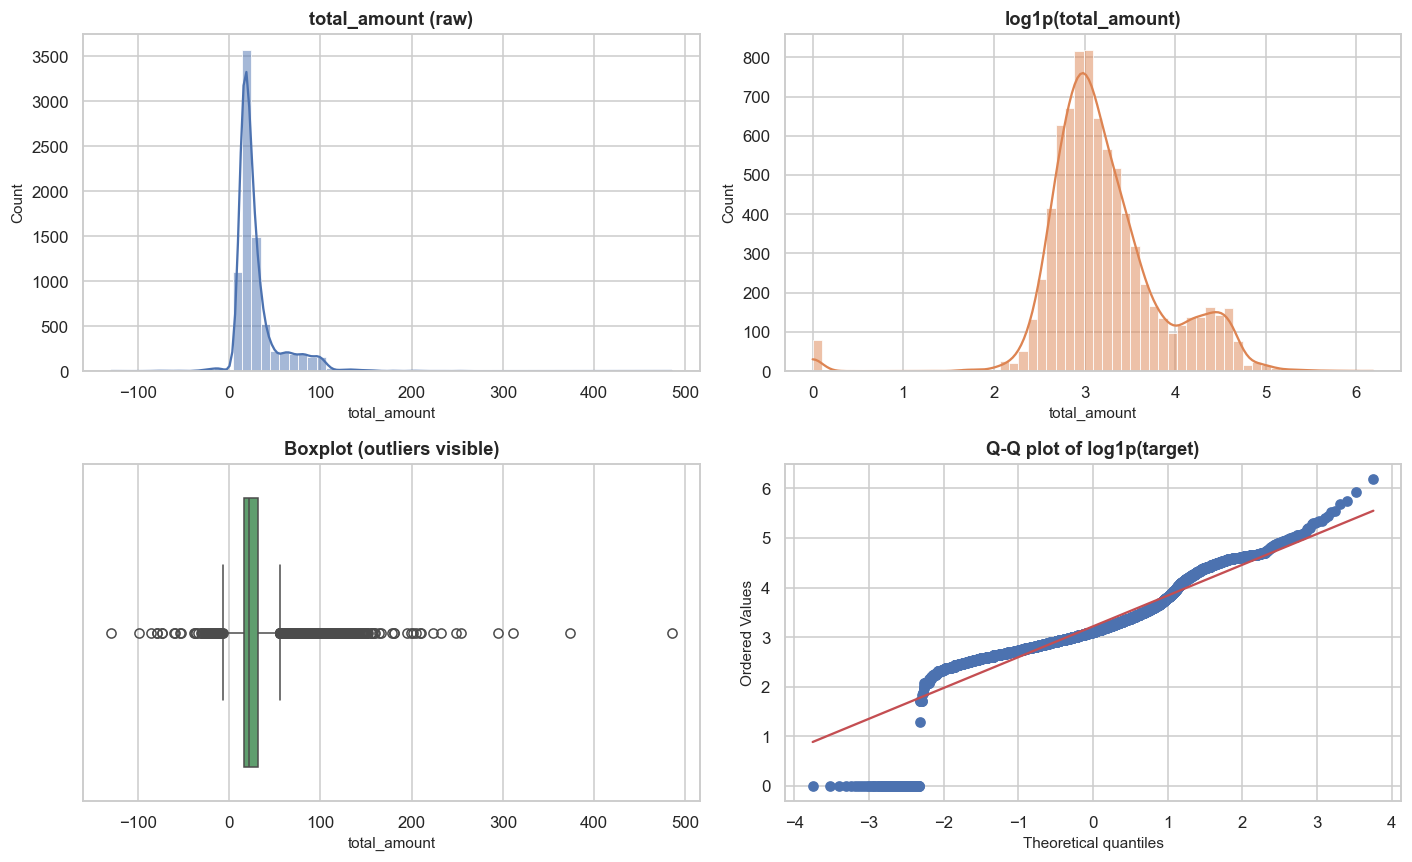

,0.000,0.001,0.010,0.050,0.250,0.500,0.750,0.950,0.990,0.999,1.000
total_amount,-129.3,-59.25,2.61,11.31,16.32,21.42,32.0,87.3,112.84,210.31,485.1


In [5]:
y = train_raw[TARGET]
print(y.describe().round(2).to_string())
print(f"\nSkewness: {y.skew():.2f} | Excess kurtosis: {y.kurt():.2f}")

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
sns.histplot(y, bins=60, kde=True, ax=ax[0, 0]); ax[0, 0].set_title("total_amount (raw)")
sns.histplot(np.log1p(y.clip(lower=0)), bins=60, kde=True, ax=ax[0, 1], color="C1")
ax[0, 1].set_title("log1p(total_amount)")
sns.boxplot(x=y, ax=ax[1, 0], color="C2"); ax[1, 0].set_title("Boxplot (outliers visible)")
stats.probplot(np.log1p(y.clip(lower=0)), plot=ax[1, 1]); ax[1, 1].set_title("Q-Q plot of log1p(target)")
plt.tight_layout(); plt.show()

pct = y.quantile([0, .001, .01, .05, .25, .5, .75, .95, .99, .999, 1]).round(2)
display(pct.to_frame("total_amount").T)

## 4. Data-quality audit
We first derive time-based fields (needed to detect impossible trips), then **count** every suspicious pattern *before* touching the data.

,rows,% of train
total_amount <= 0,80,1.00
invalid timestamp,0,0.00
dropoff before/at pickup,3087,38.59
duration > 360 min,4,0.05
trip_distance == 0,125,1.56
trip_distance > 100 mi,0,0.00
passenger_count == 0,139,1.74
structured-missing block,290,3.62
RatecodeID == 99 (unknown),30,0.38
negative non-tip surcharge,78,0.98


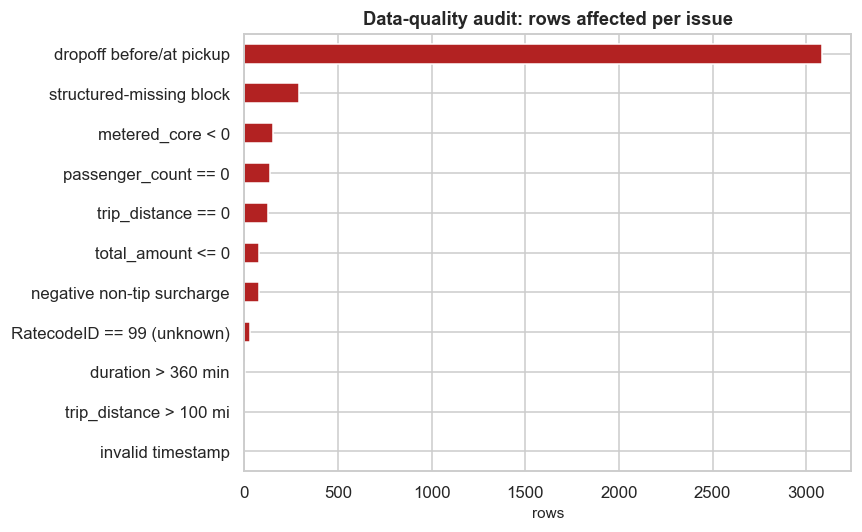

Dropoff <= pickup: 38.6% of trips
corr(distance, duration) on rows with positive duration: 0.154
corr(distance, |duration|) on all rows                 : 0.129
Pickup range: 2023-06-28 15:31:32 -> 2023-07-01 00:48:35


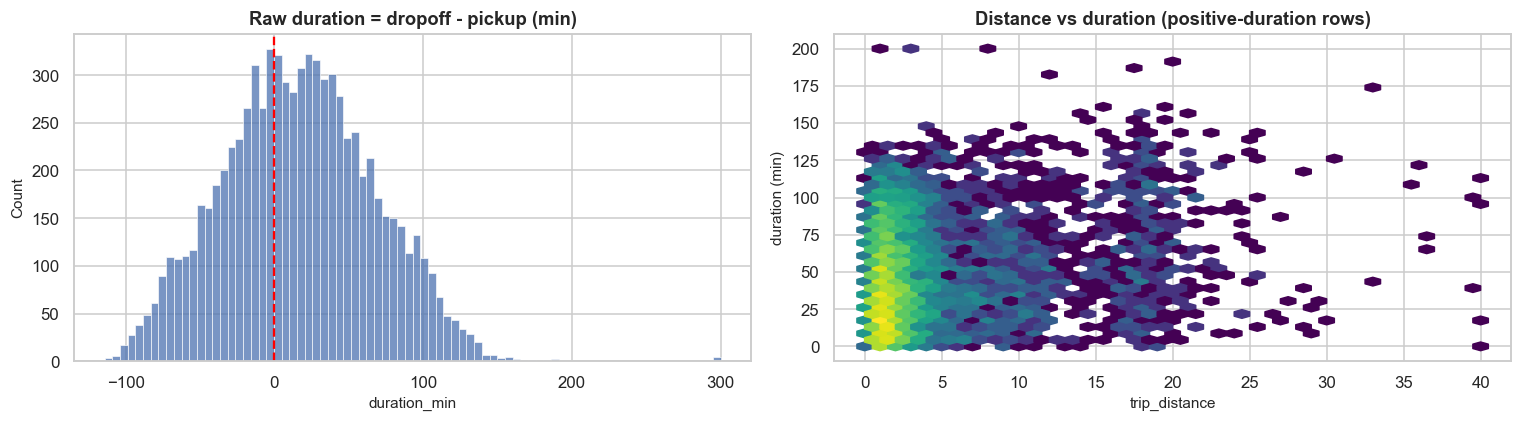

In [6]:
def add_base(df):
    d = df.copy()
    d["pickup"]  = pd.to_datetime(d["tpep_pickup_datetime"],  errors="coerce")
    d["dropoff"] = pd.to_datetime(d["tpep_dropoff_datetime"], errors="coerce")
    d["duration_min"] = (d["dropoff"] - d["pickup"]).dt.total_seconds() / 60
    d["abs_duration_min"] = d["duration_min"].abs()
    d["duration_invalid"] = (d["duration_min"] <= 0).astype(int)
    d["date"] = d["pickup"].dt.date.astype(str)
    d["hour"] = d["pickup"].dt.hour
    d["dow"]  = d["pickup"].dt.dayofweek
    d["is_weekend"] = d["dow"].isin([5, 6]).astype(int)
    d["is_rush"] = ((d["dow"] < 5) & d["hour"].isin([7, 8, 9, 16, 17, 18, 19])).astype(int)
    d["surcharge_sum"] = d[SURCHARGES].fillna(0).sum(axis=1)
    if TARGET in d.columns:
        d["metered_core"] = d[TARGET] - d["surcharge_sum"]   # distance/time-driven part of the fare
    return d

train = add_base(train_raw)
test  = add_base(test_raw)

audit = {
    "total_amount <= 0":            (train[TARGET] <= 0).sum(),
    "invalid timestamp":            train["duration_min"].isna().sum(),
    "dropoff before/at pickup":     (train["duration_min"] <= 0).sum(),
    "duration > 360 min":           (train["duration_min"] > 360).sum(),
    "trip_distance == 0":           (train["trip_distance"] == 0).sum(),
    "trip_distance > 100 mi":       (train["trip_distance"] > 100).sum(),
    "passenger_count == 0":         (train["passenger_count"] == 0).sum(),
    "structured-missing block":     (train["passenger_count"].isna() & train["RatecodeID"].isna() & train["congestion_surcharge"].isna()).sum(),
    "RatecodeID == 99 (unknown)":   (train["RatecodeID"] == 99).sum(),
    "negative non-tip surcharge":   (train[NON_TIP] < 0).any(axis=1).sum(),
    "metered_core < 0":             (train["metered_core"] < 0).sum(),
}
audit = pd.Series(audit, name="rows").to_frame()
audit["% of train"] = (audit["rows"] / len(train) * 100).round(2)
display(audit)

ax = audit["rows"].sort_values().plot(kind="barh", figsize=(8, 5), color="firebrick")
ax.set_title("Data-quality audit: rows affected per issue"); ax.set_xlabel("rows")
plt.tight_layout(); plt.show()

# --- Are the timestamps trustworthy enough to derive duration / speed? ---
pos = train[train["duration_min"] > 0]
print(f"Dropoff <= pickup: {(train['duration_min'] <= 0).mean()*100:.1f}% of trips")
print(f"corr(distance, duration) on rows with positive duration: {pos[['trip_distance','duration_min']].corr().iloc[0,1]:.3f}")
print(f"corr(distance, |duration|) on all rows                 : {train[['trip_distance','abs_duration_min']].corr().iloc[0,1]:.3f}")
print("Pickup range:", train['pickup'].min(), "->", train['pickup'].max())
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(train["duration_min"].clip(-150, 300), bins=80, ax=ax[0]); ax[0].axvline(0, color="red", ls="--")
ax[0].set_title("Raw duration = dropoff - pickup (min)")
ax[1].hexbin(pos["trip_distance"].clip(upper=40), pos["duration_min"].clip(upper=200), gridsize=40, cmap="viridis", bins="log", mincnt=1)
ax[1].set_xlabel("trip_distance"); ax[1].set_ylabel("duration (min)"); ax[1].set_title("Distance vs duration (positive-duration rows)")
plt.tight_layout(); plt.show()

**Audit conclusion.** A large share of trips has a dropoff time *earlier* than the pickup time, and duration is almost uncorrelated with distance. The timestamp-derived duration is therefore **not a reliable measurement** here. Dropping those rows would delete a big part of the training set for a problem that is not in the target, so we keep them, flag them, and avoid building speed-type features from them.

## 5. Cleaning & imputation (fully logged)
**Policy** (decided from the audit, not assumed)
| Issue | Action | Reason |
|---|---|---|
| Dropoff <= pickup, implausible duration | **Keep**, add `duration_invalid` flag, use `abs_duration_min` only as a weak feature; **no speed feature** | Affects a large share of rows and carries no clean signal; deleting would waste data |
| Negative surcharges / `total_amount <= 0` (refund-type trips) | **Keep as a separate regime** with `is_refund` flag (switch `DROP_REFUNDS` for experiments) | Identified from *features* (negative surcharge), so the same rows will appear in test and must be predictable |
| Block of rows where `passenger_count`, `RatecodeID`, `store_and_fwd_flag`, `congestion_surcharge`, `Airport_fee` are all missing | Impute (median / mode / 0) **and** add `is_missing_block` | Missingness is structural (one payment channel), so it carries information |
| `passenger_count == 0` | Treat as missing, impute median, flag | Physically impossible |
| `RatecodeID == 99` | Keep as its own category + `rate_unknown` flag | Documented "unknown" code, behaves like a normal trip |
| Extreme distance / duration | **Winsorise** into `*_clip` columns (0.5-99.5 pct, fitted on train) | Robust inputs; raw values stay available |
| Exact duplicates | Drop from train | No information |

The test set is **never** filtered. Only the same train-fitted imputation is applied.

In [7]:
DROP_REFUNDS = False   # experiment switch for Part 2; default keeps the refund regime and models it explicitly

RULES = [("exact duplicate rows", lambda d: d.duplicated(keep="first"))]
if DROP_REFUNDS:
    RULES.append(("negative-surcharge (refund) trips", lambda d: (d[NON_TIP] < 0).any(axis=1)))

def clean_train(df):
    d = df.copy()
    log = [("start", len(d), 0)]
    for name, rule in RULES:
        mask = rule(d)
        log.append((name, len(d) - int(mask.sum()), int(mask.sum())))
        d = d[~mask]
    return d.reset_index(drop=True), pd.DataFrame(log, columns=["rule", "rows_remaining", "rows_dropped"])

train_c, clean_log = clean_train(train)
display(clean_log)
print(f"Kept {len(train_c)}/{len(train)} rows ({len(train_c)/len(train)*100:.2f}%)")

,rule,rows_remaining,rows_dropped
0,start,8000,0
1,exact duplicate rows,8000,0


Kept 8000/8000 rows (100.00%)


In [8]:
# ---- fit imputation / clipping statistics on cleaned TRAIN only ----
pc = train_c["passenger_count"].where(train_c["passenger_count"] > 0)
FILL = {
    "passenger_count":    pc.median(),
    "RatecodeID":         train_c["RatecodeID"].mode()[0],
    "payment_type":       train_c["payment_type"].mode()[0],
    "VendorID":           train_c["VendorID"].mode()[0],
    "store_and_fwd_flag": train_c["store_and_fwd_flag"].mode()[0],
    "abs_duration_min":   train_c["abs_duration_min"].median(),
    "trip_distance":      train_c["trip_distance"].median(),
}
CLIP_COLS = ["trip_distance", "abs_duration_min"]
CLIP_BOUNDS = {c: (train_c[c].quantile(0.005), train_c[c].quantile(0.995)) for c in CLIP_COLS}
display(pd.Series(FILL, name="fill value").to_frame())
display(pd.DataFrame(CLIP_BOUNDS, index=["lower", "upper"]).T.round(2))

def apply_prep(df):
    d = df.copy()
    # flags are created BEFORE imputation so the information is not lost
    d["is_refund"]        = (d[NON_TIP] < 0).any(axis=1).astype(int)
    d["is_missing_block"] = (d["RatecodeID"].isna() & d["congestion_surcharge"].isna()).astype(int)
    d["rate_unknown"]     = (d["RatecodeID"] == 99).astype(int)
    d["zero_distance"]    = (d["trip_distance"] == 0).astype(int)
    d["passenger_count_missing"] = (d["passenger_count"].isna() | (d["passenger_count"] <= 0)).astype(int)
    d.loc[d["passenger_count"] <= 0, "passenger_count"] = np.nan
    for c, v in FILL.items():
        d[c] = d[c].fillna(v)
    d[SURCHARGES] = d[SURCHARGES].fillna(0)
    d["surcharge_sum"] = d[SURCHARGES].sum(axis=1)
    if TARGET in d.columns:
        d["metered_core"] = d[TARGET] - d["surcharge_sum"]
    for c, (lo, hi) in CLIP_BOUNDS.items():
        d[c + "_clip"] = d[c].clip(lo, hi)
    return d

train_p = apply_prep(train_c)
test_p  = apply_prep(test)
assert test_p.shape[0] == test_raw.shape[0], "test rows must never be dropped"
FLAGS = ["is_refund", "is_missing_block", "rate_unknown", "zero_distance", "passenger_count_missing", "duration_invalid"]
display(pd.concat({"train": train_p[FLAGS].mean(), "test": test_p[FLAGS].mean()}, axis=1).mul(100).round(2).rename_axis("flag (% of rows)"))
print("Remaining NaNs  train:", int(train_p[list(FILL.keys())].isna().sum().sum()),
      "| test:", int(test_p[list(FILL.keys())].isna().sum().sum()))
train_p.to_pickle("train_clean.pkl"); test_p.to_pickle("test_clean.pkl")

,fill value
passenger_count,1.0
RatecodeID,1.0
payment_type,Credit Card
VendorID,1
store_and_fwd_flag,N
abs_duration_min,36.475
trip_distance,1.83


,lower,upper
trip_distance,0.00,24.73
abs_duration_min,0.35,137.37


,train,test
flag (% of rows),,
is_refund,0.98,1.1
is_missing_block,3.62,3.8
rate_unknown,0.38,0.3
zero_distance,1.56,1.4
passenger_count_missing,5.36,5.5
duration_invalid,38.59,37.5


Remaining NaNs  train: 0 | test: 0


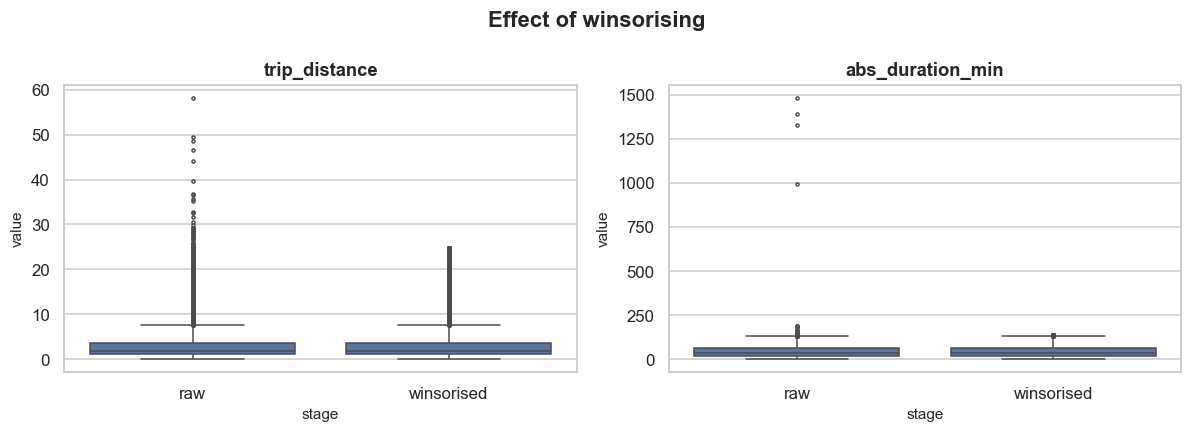

In [9]:
# Effect of winsorising on the two noisy numeric inputs
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, c in zip(ax, CLIP_COLS):
    data = pd.DataFrame({"value": pd.concat([train_p[c], train_p[c + "_clip"]], ignore_index=True),
                         "stage": ["raw"] * len(train_p) + ["winsorised"] * len(train_p)})
    sns.boxplot(data=data, x="stage", y="value", ax=a, fliersize=2); a.set_title(c)
plt.suptitle("Effect of winsorising", fontweight="bold"); plt.tight_layout(); plt.show()

## 6. Temporal analysis
Taxi demand follows a strong daily rhythm. Note that the data covers only a few calendar days, so **hour of day** is informative while day-of-week / month carry little.

Pickup range: 2023-06-28 15:31:32 -> 2023-07-01 00:48:35 | distinct dates: 4


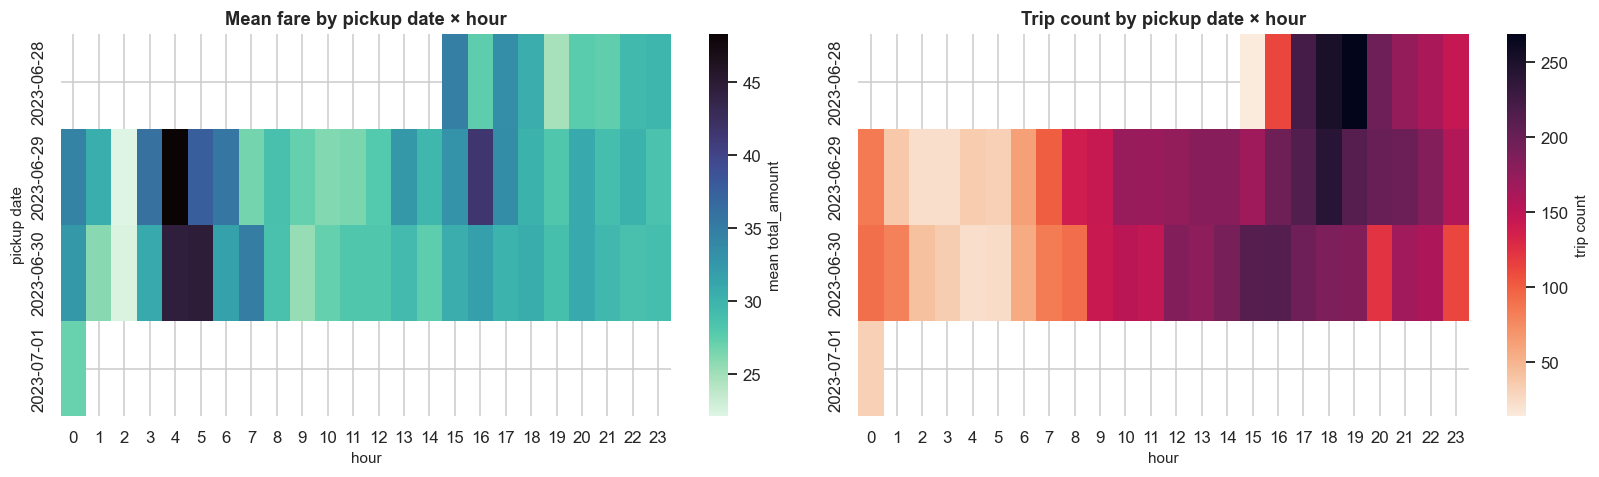

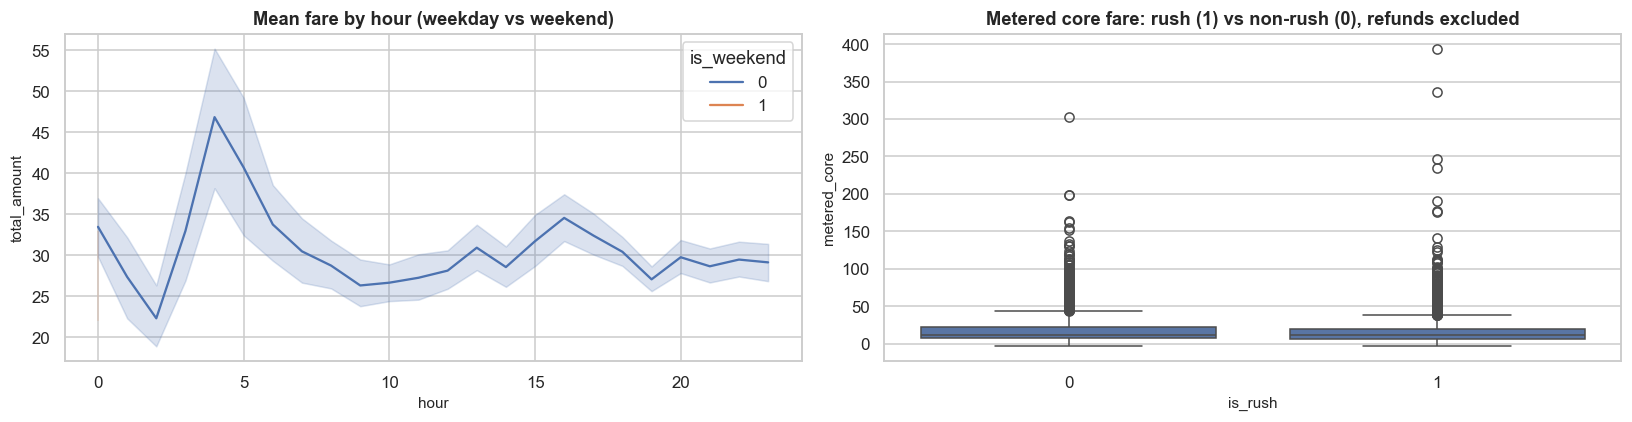

In [10]:
print("Pickup range:", train_p["pickup"].min(), "->", train_p["pickup"].max(), "| distinct dates:", train_p["date"].nunique())
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
pt = train_p.pivot_table(index="date", columns="hour", values=TARGET, aggfunc="mean")
sns.heatmap(pt, cmap="mako_r", ax=ax[0], cbar_kws={"label": "mean total_amount"})
ax[0].set_title("Mean fare by pickup date × hour"); ax[0].set_ylabel("pickup date")
ct = train_p.pivot_table(index="date", columns="hour", values=TARGET, aggfunc="size")
sns.heatmap(ct, cmap="rocket_r", ax=ax[1], cbar_kws={"label": "trip count"})
ax[1].set_title("Trip count by pickup date × hour"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.lineplot(data=train_p, x="hour", y=TARGET, hue="is_weekend", estimator="mean", errorbar=("ci", 95), ax=ax[0])
ax[0].set_title("Mean fare by hour (weekday vs weekend)")
sns.boxplot(data=train_p[train_p["is_refund"] == 0], x="is_rush", y="metered_core", ax=ax[1])
ax[1].set_title("Metered core fare: rush (1) vs non-rush (0), refunds excluded")
plt.tight_layout(); plt.show()

## 7. Distance and duration
The fare meter is mostly a function of distance, so this relationship carries most of the signal. Duration is shown for completeness but was shown to be unreliable in Section 4.

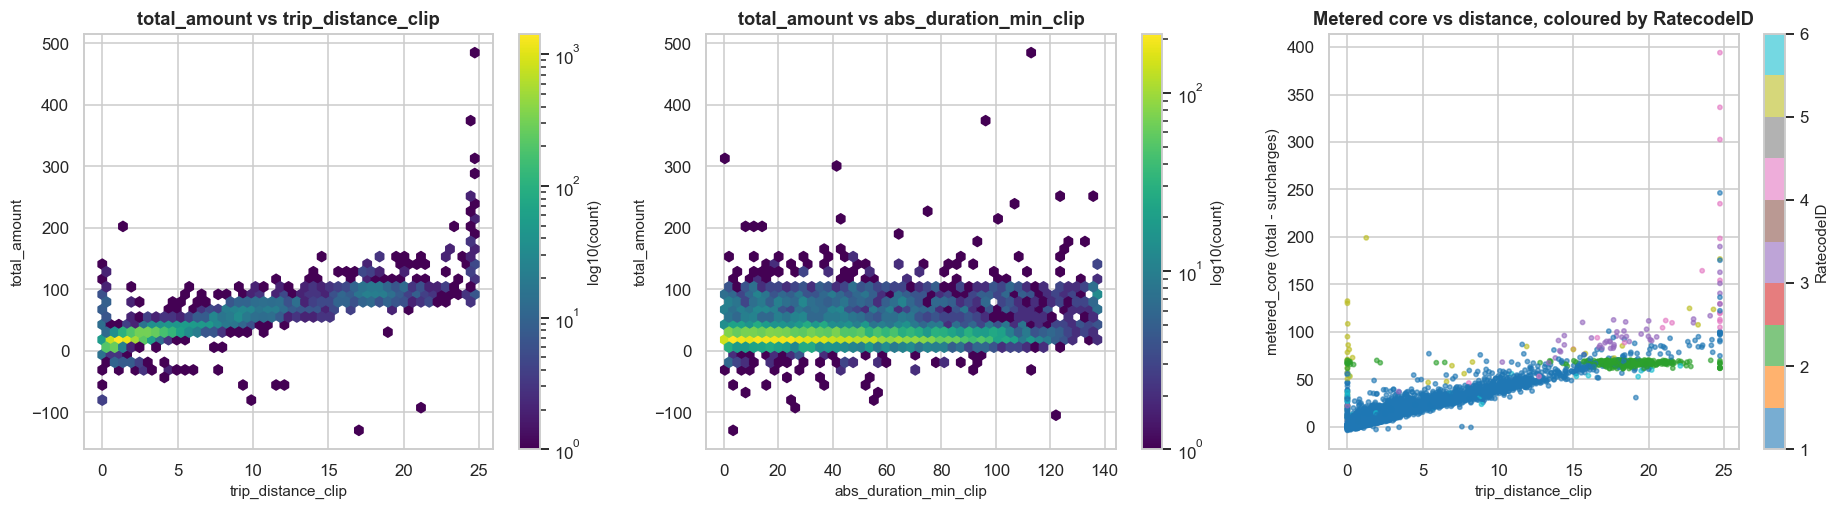

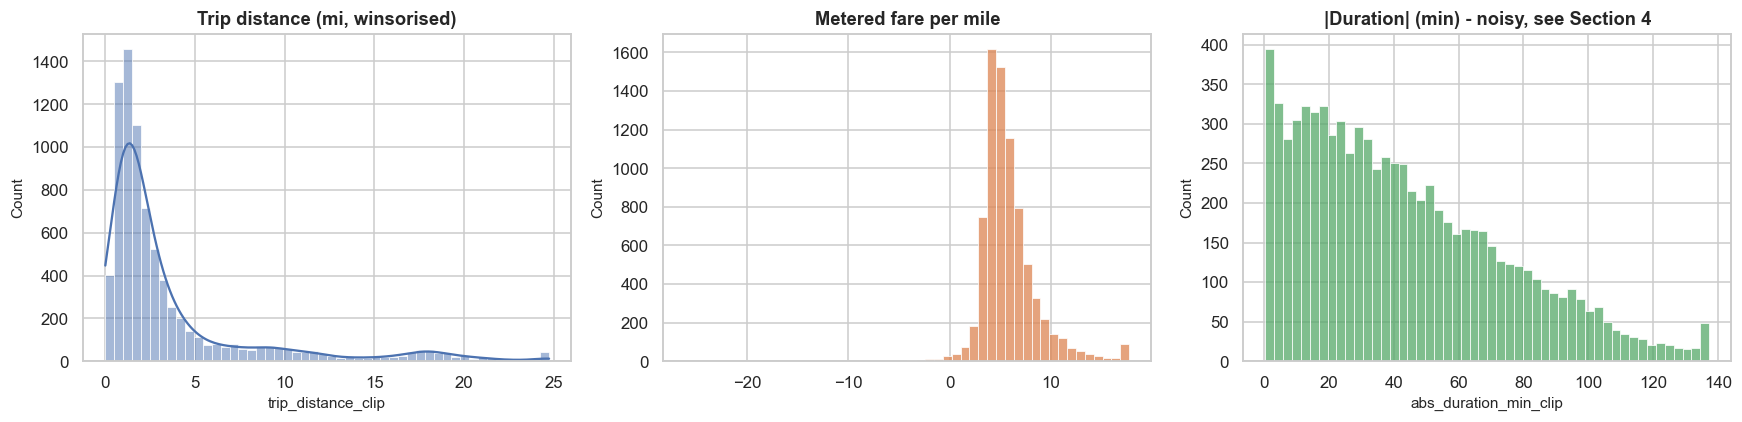

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for a, x in zip(ax[:2], ["trip_distance_clip", "abs_duration_min_clip"]):
    hb = a.hexbin(train_p[x], train_p[TARGET], gridsize=45, cmap="viridis", bins="log", mincnt=1)
    a.set_xlabel(x); a.set_ylabel(TARGET); a.set_title(f"{TARGET} vs {x}")
    plt.colorbar(hb, ax=a, label="log10(count)")
reg = train_p[train_p["is_refund"] == 0]        # refunds are analysed separately in 8b
sc = ax[2].scatter(reg["trip_distance_clip"], reg["metered_core"],
                   c=reg["RatecodeID"].clip(upper=6), cmap="tab10", s=8, alpha=.6)
ax[2].set_xlabel("trip_distance_clip"); ax[2].set_ylabel("metered_core (total - surcharges)")
ax[2].set_title("Metered core vs distance, coloured by RatecodeID")
plt.colorbar(sc, ax=ax[2], label="RatecodeID")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(train_p["trip_distance_clip"], bins=50, kde=True, ax=ax[0]); ax[0].set_title("Trip distance (mi, winsorised)")
fpm = (reg["metered_core"] / reg["trip_distance"].replace(0, np.nan)).replace([np.inf, -np.inf], np.nan).dropna()
sns.histplot(fpm.clip(upper=fpm.quantile(.99)), bins=50, ax=ax[1], color="C1"); ax[1].set_title("Metered fare per mile")
sns.histplot(train_p["abs_duration_min_clip"], bins=50, ax=ax[2], color="C2"); ax[2].set_title("|Duration| (min) - noisy, see Section 4")
plt.tight_layout(); plt.show()

## 8. Categorical analysis

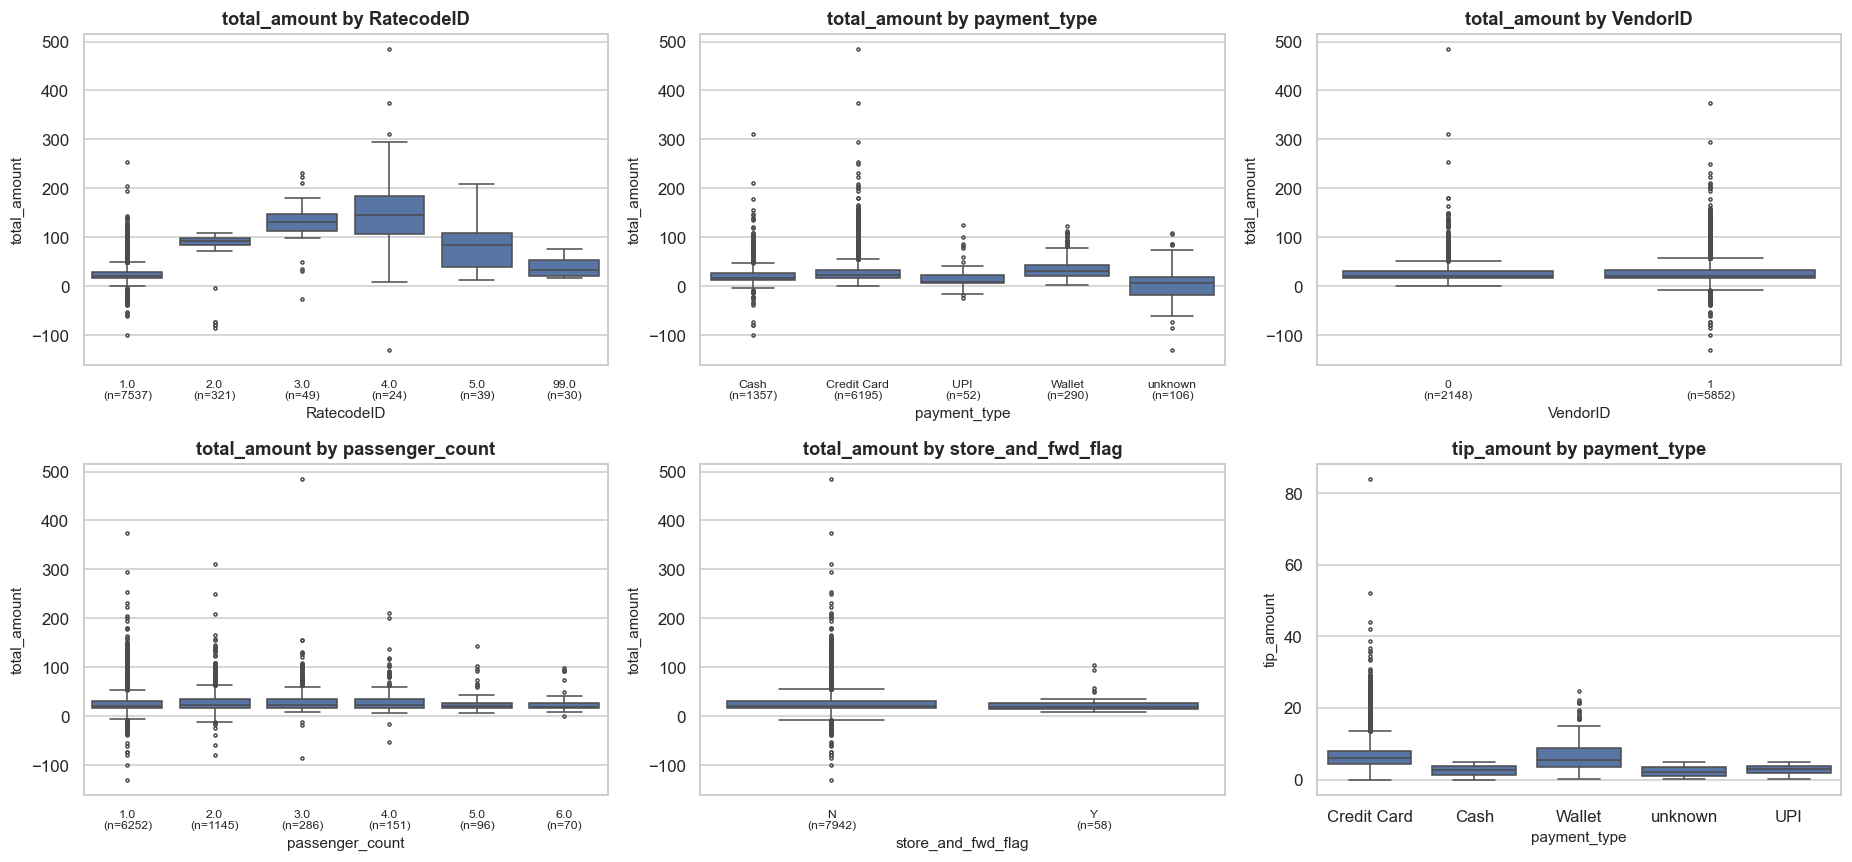

total_amount         trip_distance        tip_amount       
                  count    mean         count   mean      count   mean
RatecodeID                                                            
1.0                7537   25.99          7537   2.95       7537   5.70
2.0                 321   89.32           321  17.38        321  12.85
3.0                  49  127.76            49  17.83         49  17.04
4.0                  24  161.53            24  25.65         24  21.16
5.0                  39   85.71            39   5.69         39   9.65
99.0                 30   37.58            30   6.57         30   2.72

In [12]:
cats = ["RatecodeID", "payment_type", "VendorID", "passenger_count", "store_and_fwd_flag"]
fig, ax = plt.subplots(2, 3, figsize=(17, 8)); ax = ax.ravel()
for a, c in zip(ax, cats):
    order = sorted(train_p[c].unique())
    sns.boxplot(data=train_p, x=c, y=TARGET, order=order, ax=a, fliersize=2)
    n = train_p[c].value_counts()
    a.set_xticklabels([f"{o}\n(n={n[o]})" for o in order], fontsize=8)
    a.set_title(f"{TARGET} by {c}")
sns.boxplot(data=train_p, x="payment_type", y="tip_amount", ax=ax[-1], fliersize=2); ax[-1].set_title("tip_amount by payment_type")
plt.tight_layout(); plt.show()
display(train_p.groupby("RatecodeID")[[TARGET, "trip_distance", "tip_amount"]].agg(["count", "mean"]).round(2))

## 8b. Refund (negative-fare) regime & fare additivity
Some trips have a **negative total**. If those can be recognised from *features* available in test (negative surcharges), the model can learn them instead of treating them as noise. We also test whether the fare is *additive* (total = distance part + surcharges + tip), which decides how we build the target in Part 2.

total_amount <= 0   False  True 
negative surcharge              
0                    7920      2
1                       0     78
Refund-type trips: 78 (0.97%) | payment types: {'unknown': 49, 'Cash': 20, 'UPI': 9}


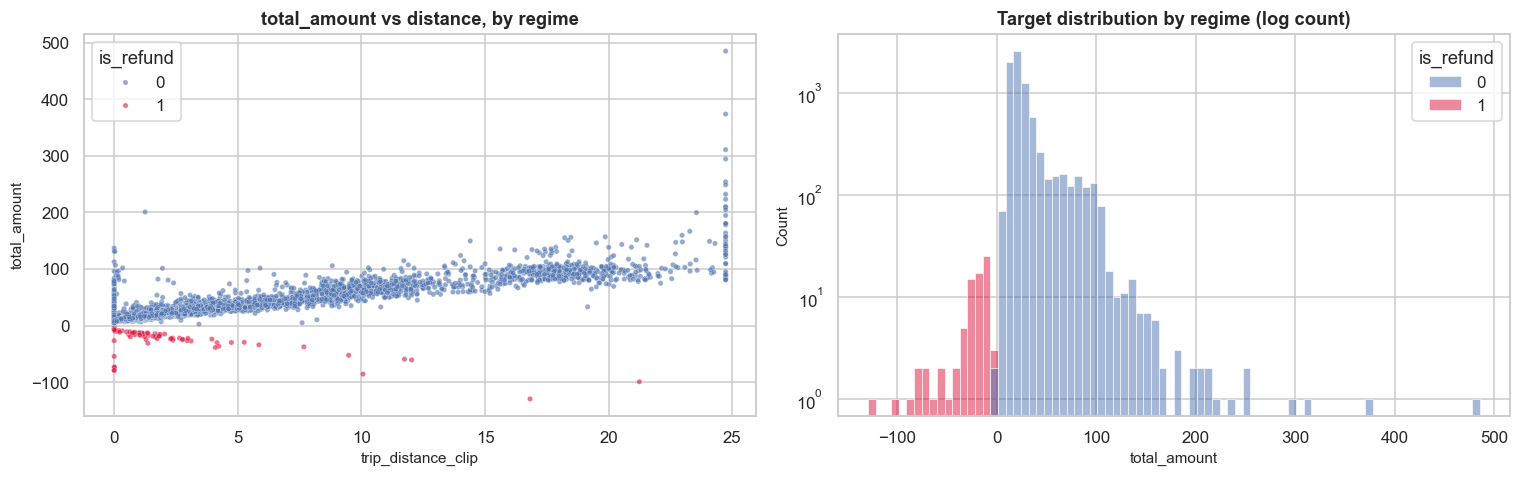

,OLS coefficient
intercept,2.64
trip_distance,4.12
extra,0.52
tolls_amount,0.87
congestion_surcharge,1.96
Airport_fee,1.36
tip_amount,0.96


Standard-rate trips: n=7113 | R2 = 0.940 | RMSE = 4.17
Coefficients near 1 on a surcharge/tip column mean it is added to the fare one-for-one.


In [13]:
print(pd.crosstab(train_p["is_refund"], train_p[TARGET] <= 0, rownames=["negative surcharge"], colnames=["total_amount <= 0"]))
ref = train_p[train_p["is_refund"] == 1]
print(f"Refund-type trips: {len(ref)} ({len(ref)/len(train_p)*100:.2f}%) | payment types: {ref['payment_type'].value_counts().to_dict()}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(data=train_p, x="trip_distance_clip", y=TARGET, hue="is_refund", palette={0: "C0", 1: "crimson"}, s=12, alpha=.6, ax=ax[0])
ax[0].set_title("total_amount vs distance, by regime")
sns.histplot(data=train_p, x=TARGET, hue="is_refund", bins=80, palette={0: "C0", 1: "crimson"}, ax=ax[1])
ax[1].set_yscale("log"); ax[1].set_title("Target distribution by regime (log count)")
plt.tight_layout(); plt.show()

normal = train_p[(train_p["is_refund"] == 0) & (train_p[TARGET] > 0) & (train_p["RatecodeID"] == 1)
                 & (train_p["trip_distance"] > 0) & (train_p["is_missing_block"] == 0)]
cols = ["trip_distance", "extra", "tolls_amount", "congestion_surcharge", "Airport_fee", "tip_amount"]
X = np.c_[np.ones(len(normal)), normal[cols].values]
beta = np.linalg.lstsq(X, normal[TARGET].values, rcond=None)[0]
resid = normal[TARGET].values - X @ beta
display(pd.Series(beta, index=["intercept"] + cols, name="OLS coefficient").round(2).to_frame())
print(f"Standard-rate trips: n={len(normal)} | R2 = {1 - resid.var()/normal[TARGET].var():.3f} | RMSE = {resid.std():.2f}")
print("Coefficients near 1 on a surcharge/tip column mean it is added to the fare one-for-one.")

## 9. Spatial (zone) analysis
Location IDs are categorical zones. We check concentration (how skewed zone traffic is) and which zones are systematically expensive. Zones with few trips are marked unreliable, which motivates **frequency encoding / smoothed target encoding** in Part 2.

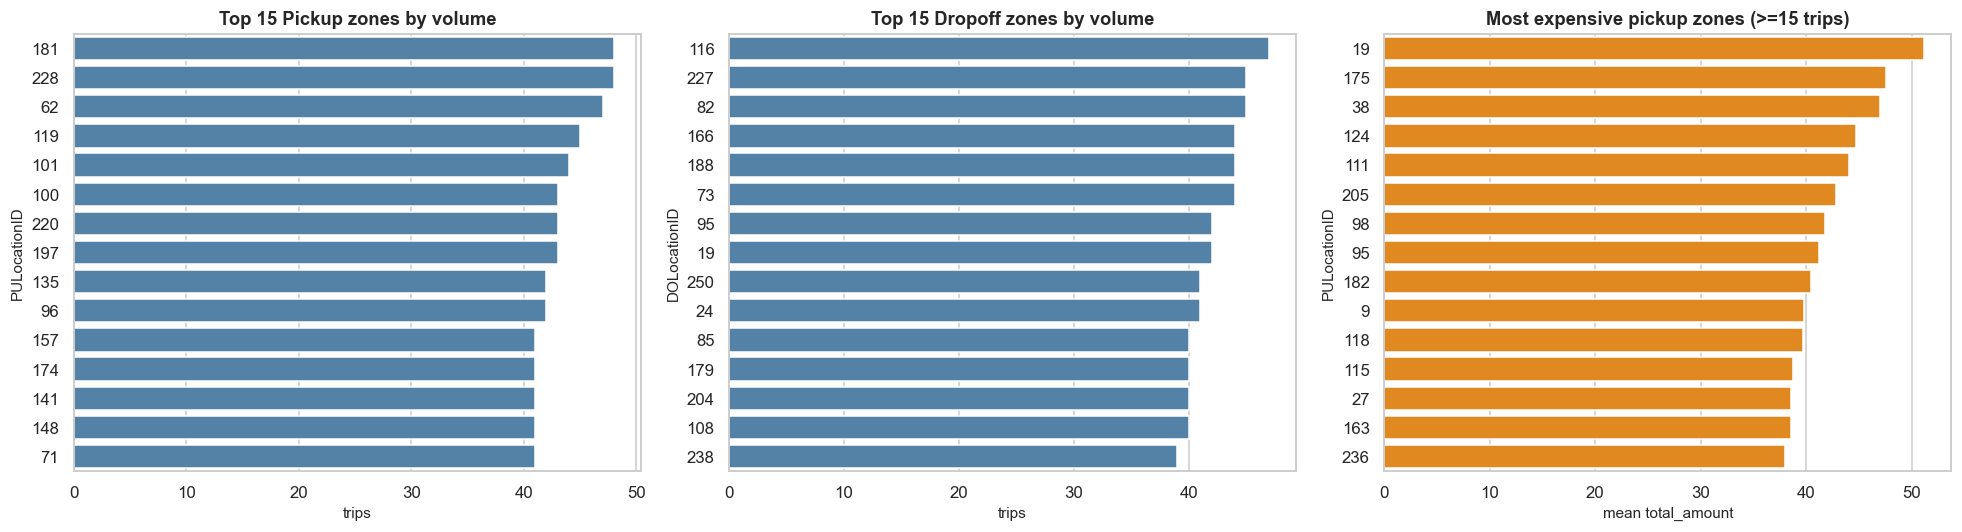

Unique PU zones: 264 | top-10 zones cover 5.6% of trips
Zones with < 10 trips: 0 (0.0% of zones)
Test pickup zones unseen in train: 0


In [14]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, col, lab in zip(ax[:2], ["PULocationID", "DOLocationID"], ["Pickup", "Dropoff"]):
    top = train_p[col].value_counts().head(15)
    sns.barplot(x=top.values, y=top.index.astype(str), ax=a, color="steelblue")
    a.set_title(f"Top 15 {lab} zones by volume"); a.set_xlabel("trips"); a.set_ylabel(col)

g = train_p.groupby("PULocationID")[TARGET].agg(["mean", "count"])
g = g[g["count"] >= 15].sort_values("mean", ascending=False).head(15)
sns.barplot(x=g["mean"].values, y=g.index.astype(str), ax=ax[2], color="darkorange")
ax[2].set_title("Most expensive pickup zones (>=15 trips)"); ax[2].set_xlabel("mean total_amount")
plt.tight_layout(); plt.show()

vc = train_p["PULocationID"].value_counts()
print(f"Unique PU zones: {len(vc)} | top-10 zones cover {vc.head(10).sum()/len(train_p)*100:.1f}% of trips")
print(f"Zones with < 10 trips: {(vc < 10).sum()} ({(vc < 10).mean()*100:.1f}% of zones)")
unseen = set(test_p['PULocationID']) - set(train_p['PULocationID'])
print(f"Test pickup zones unseen in train: {len(unseen)}")

## 10. Correlation analysis

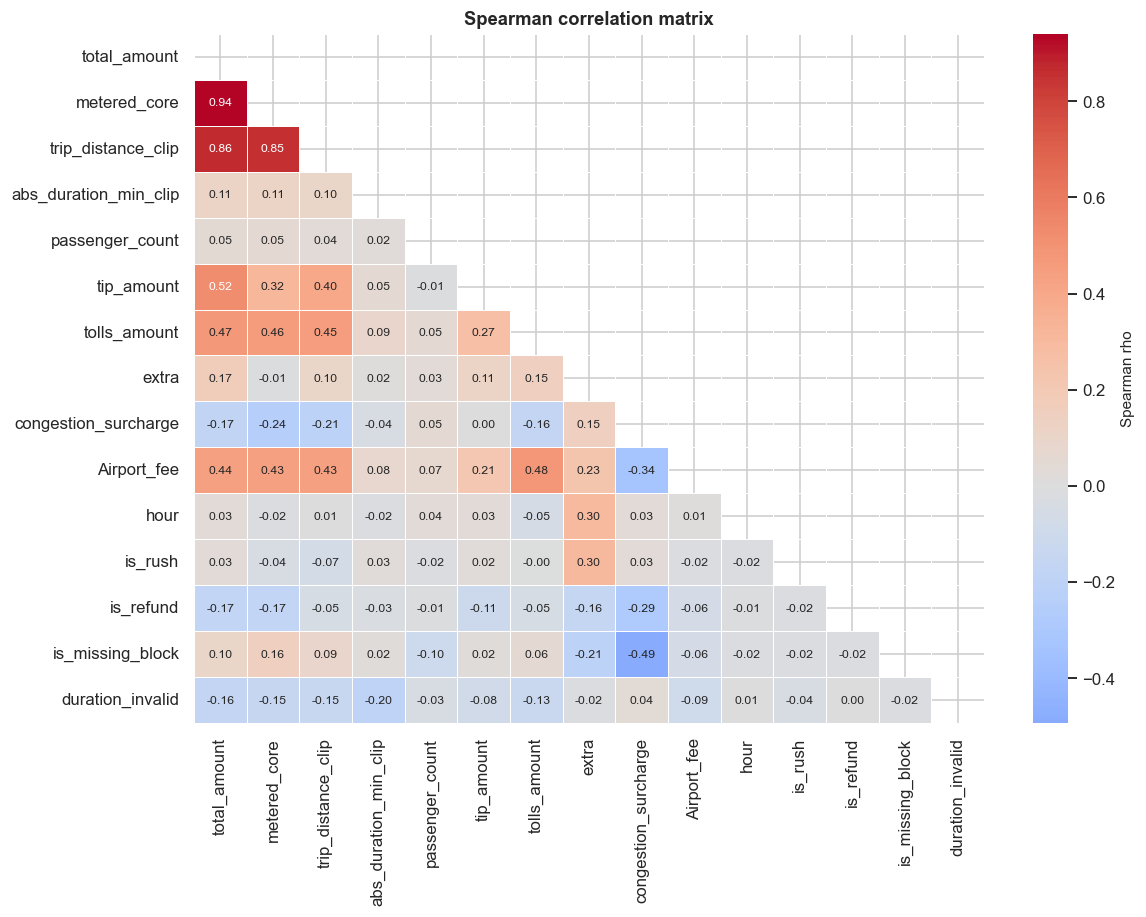

,rho with target
metered_core,0.941
trip_distance_clip,0.863
tip_amount,0.522
tolls_amount,0.475
Airport_fee,0.436
congestion_surcharge,-0.175
is_refund,-0.170
extra,0.166
duration_invalid,-0.159
abs_duration_min_clip,0.114


In [15]:
num = [TARGET, "metered_core", "trip_distance_clip", "abs_duration_min_clip", "passenger_count",
       "tip_amount", "tolls_amount", "extra", "congestion_surcharge", "Airport_fee",
       "hour", "is_rush", "is_refund", "is_missing_block", "duration_invalid"]
corr = train_p[num].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(11, 8.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5,
            annot_kws={"size": 8}, cbar_kws={"label": "Spearman rho"})
plt.title("Spearman correlation matrix"); plt.tight_layout(); plt.show()
display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_frame("rho with target"))

## 11. Train vs test distribution check
A model is only as good as the similarity between train and test. We (a) run Kolmogorov–Smirnov tests on numeric features and (b) run **adversarial validation**: a classifier tries to tell train rows from test rows. An AUC near 0.5 means the two sets are indistinguishable, so ordinary K-Fold CV will reflect the leaderboard.

In [ ]:
cmp_cols = ["trip_distance", "abs_duration_min", "passenger_count", "hour", "dow", "is_refund"] + SURCHARGES
rows = []
for c in cmp_cols:
    ks = stats.ks_2samp(train_p[c].dropna(), test_p[c].dropna())
    rows.append((c, train_p[c].mean(), test_p[c].mean(), ks.statistic, ks.pvalue))
ks_df = pd.DataFrame(rows, columns=["feature", "train_mean", "test_mean", "KS_stat", "p_value"]).round(4)
display(ks_df)

adv_feats = ["trip_distance", "abs_duration_min", "passenger_count", "hour", "dow",
             "RatecodeID", "payment_type", "PULocationID", "DOLocationID"] + SURCHARGES
X_adv = pd.concat([train_p[adv_feats], test_p[adv_feats]], ignore_index=True)
X_adv["payment_type"] = X_adv["payment_type"].astype("category").cat.codes
y_adv = np.r_[np.zeros(len(train_p)), np.ones(len(test_p))]
clf = HistGradientBoostingClassifier(max_iter=200, random_state=SEED)
p = cross_val_predict(clf, X_adv, y_adv, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                      method="predict_proba")[:, 1]
auc = roc_auc_score(y_adv, p)
print(f"Adversarial validation AUC = {auc:.3f}  (0.5 = no shift)")
print("Verdict:", "No meaningful shift -> standard KFold is a faithful CV." if auc < 0.6
      else "Shift detected -> inspect drivers and consider a CV that mimics the test split.")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, c in zip(ax, ["trip_distance", "abs_duration_min", "hour"]):
    sns.kdeplot(train_p[c], ax=a, label="train", fill=True, alpha=.3)
    sns.kdeplot(test_p[c],  ax=a, label="test",  fill=True, alpha=.3)
    a.set_title(c); a.legend()
plt.tight_layout(); plt.show()

## 12. Key findings & modelling plan

**Data quality (measured on train, 8,000 trips)**
- **Timestamps are unreliable**: 38.6% of trips have dropoff <= pickup and duration is almost uncorrelated with distance (rho ~ 0.13-0.15). We therefore keep those rows, add `duration_invalid`, and deliberately **do not build a speed feature**.
- **Structured missingness**: 290 rows (3.6%) have `passenger_count`, `RatecodeID`, `store_and_fwd_flag`, `congestion_surcharge` and `Airport_fee` missing *together*; these are exactly the `Wallet` payments. Imputed + flagged with `is_missing_block`.
- **Refund-type trips**: 78 trips (0.98%) carry a negative surcharge and a negative total; they are identified purely from features, so they are kept as their own regime (`is_refund`). Two further non-positive totals have no negative surcharge.
- Smaller issues: 139 trips with 0 passengers, 125 with 0 distance, 30 with unknown `RatecodeID == 99`.
- **Heavy-tailed target**: skew 3.2, excess kurtosis 25, range -129 to 485; 28 trips exceed 150. These dominate RMSE, so validation must be stratified by target level.
- Pickups cover only 4 calendar dates (28 Jun - 1 Jul 2023): hour of day is useful, day-of-week / month are not.

**Signal**
- Distance dominates (Spearman rho ~ 0.86 with the target). Rate codes 2/3/4 (JFK / Newark / Nassau-Westchester under standard TLC coding) have mean fares of ~89 / ~128 / ~162 versus ~26 for the standard rate.
- Fares are close to **additive**: for standard-rate trips an OLS on distance + surcharges + tip reaches R2 = 0.94 (RMSE 4.17), with a tip coefficient ~ 0.96.
- Tips depend strongly on payment type (cash / UPI / unknown tips stay small).

**Train vs test**
- Adversarial validation AUC on the real test set: [fill after running on Kaggle] -> [conclusion on CV choice]. KS tests are in Section 11.

**Modelling plan (implemented in Sections 13-18)**
1. Target = `total_amount - surcharge_sum` (`metered_core`), add `surcharge_sum` back; keep `is_refund` rows and model them via a sign-flipped target (and optionally compare against `DROP_REFUNDS=True`).
2. Features: distance (raw + log), rate code, airport flags, payment type, hour, zone-pair frequency, fold-wise smoothed target encoding, all flags from Section 5. No speed feature.
3. 5-fold CV **stratified by binned target** (heavy tail), multi-seed LightGBM / CatBoost / XGBoost blend.
4. Residual diagnostics by distance bucket, rate code, payment type and refund regime.

## 13. Feature engineering
Features are built from what the audit showed to be reliable. **No speed feature** (timestamps are unreliable); duration enters only as a weak `abs_duration_min` + `duration_invalid` flag.

| Group | Features |
|---|---|
| Distance | raw, `log1p`, winsorised |
| Fare structure | rate code (99 -> own bucket), airport fee, tolls, extra, congestion, tip, `surcharge_sum`, tip per mile |
| Regime flags | `is_refund`, `is_missing_block`, `rate_unknown`, `zero_distance`, `duration_invalid` |
| Time | hour, cyclic hour (sin/cos), rush flag |
| Spatial | pickup / dropoff zone, zone-pair frequency, same-zone flag, **smoothed target encoding** of pickup, dropoff and pair |

**Target:** `metered_core = total_amount - surcharge_sum` (the fare is additive, Section 8b). We predict the core and add the surcharges back, so the model only learns the uncertain part.

**Refund regime:** trips with a negative surcharge have a negative fare that mirrors a normal trip with the sign flipped. Instead of making trees learn ~80 negative examples, we train on `sign x metered_core` (sign = -1 for refunds) and flip the prediction back. In a quick experiment this cut the RMSE on refund trips by about two thirds and improved the overall RMSE; the exact numbers are in the diagnostics table below.

**Leakage control:** zone *frequencies* use train+test counts (no target involved). Target encodings are computed **inside each CV fold**: the training part uses an inner out-of-fold encoding, the validation/test part uses an encoding fitted on the training part only.

In [ ]:
from sklearn.model_selection import KFold

PAY_MAP = {p: i for i, p in enumerate(sorted(set(train_p["payment_type"]) | set(test_p["payment_type"])))}
ALL_ZONES = pd.concat([train_p, test_p], ignore_index=True)
ALL_ZONES["pair"] = ALL_ZONES["PULocationID"] * 1000 + ALL_ZONES["DOLocationID"]
FREQ = {k: ALL_ZONES[k].value_counts() for k in ["PULocationID", "DOLocationID", "pair"]}

def add_features(df):
    d = df.copy()
    d["log_dist"]  = np.log1p(d["trip_distance"])
    d["rate_code"] = d["RatecodeID"].where(d["RatecodeID"] != 99, 6)
    d["pay_code"]  = d["payment_type"].map(PAY_MAP)
    d["sf_flag"]   = (d["store_and_fwd_flag"] == "Y").astype(int)
    d["pair"]      = d["PULocationID"] * 1000 + d["DOLocationID"]
    d["same_zone"] = (d["PULocationID"] == d["DOLocationID"]).astype(int)
    d["tip_per_mile"] = d["tip_amount"] / (d["trip_distance"] + 1)
    d["hour_sin"] = np.sin(2 * np.pi * d["hour"] / 24)
    d["hour_cos"] = np.cos(2 * np.pi * d["hour"] / 24)
    for c in NON_TIP:
        d[c + "_abs"] = d[c].abs()          # lets trees see the size of a surcharge irrespective of refund sign
    for k in ["PULocationID", "DOLocationID", "pair"]:
        d[k + "_freq"] = d[k].map(FREQ[k]).fillna(0)
    return d

train_f = add_features(train_p)
test_f  = add_features(test_p)

BASE_FEATS = ["trip_distance", "log_dist", "trip_distance_clip", "abs_duration_min_clip", "duration_invalid",
              "passenger_count", "rate_code", "VendorID", "pay_code", "sf_flag",
              "extra", "tip_amount", "tolls_amount", "improvement_surcharge", "congestion_surcharge",
              "Airport_fee", "surcharge_sum", "tip_per_mile",
              "is_refund", "is_missing_block", "rate_unknown", "zero_distance", "passenger_count_missing",
              "hour", "hour_sin", "hour_cos", "is_rush", "same_zone",
              "PULocationID", "DOLocationID", "PULocationID_freq", "DOLocationID_freq", "pair_freq"] + [c + "_abs" for c in NON_TIP]
TE_KEYS = {"te_PU": "PULocationID", "te_DO": "DOLocationID", "te_pair": "pair"}
FEATS = BASE_FEATS + list(TE_KEYS)

y_total = train_f[TARGET]
y_core  = train_f["metered_core"]
# Refund trips mirror normal trips with a flipped sign, so models learn sign * core and the sign is restored afterwards
SIGN   = np.where(train_f["is_refund"] == 1, -1.0, 1.0)
SIGN_T = np.where(test_f["is_refund"] == 1, -1.0, 1.0)
y_model = y_core * SIGN

def _te_map(keys, y, m):
    prior = y.mean()
    g = pd.DataFrame({"k": keys.values, "y": y.values}).groupby("k")["y"].agg(["sum", "count"])
    return (g["sum"] + m * prior) / (g["count"] + m), prior

def te_apply(df, fit_df, y_fit, m=20):
    out = pd.DataFrame(index=df.index)
    for name, col in TE_KEYS.items():
        mp, prior = _te_map(fit_df[col], y_fit, m)
        out[name] = df[col].map(mp).fillna(prior)
    return out

def te_oof(fit_df, y_fit, n_splits=5, m=20):
    out = pd.DataFrame(index=fit_df.index, columns=list(TE_KEYS), dtype=float)
    for a, b in KFold(n_splits, shuffle=True, random_state=SEED).split(fit_df):
        out.iloc[b] = te_apply(fit_df.iloc[b], fit_df.iloc[a], y_fit.iloc[a], m).values
    return out

print(f"{len(FEATS)} features | train {train_f.shape} | test {test_f.shape}")
assert train_f[BASE_FEATS].isna().sum().sum() == 0 and test_f[BASE_FEATS].isna().sum().sum() == 0

## 14. Cross-validation framework
- **5-fold, stratified on decile bins of `total_amount`.** The target is heavy-tailed (a handful of very expensive trips), so plain K-Fold can put most of them in one fold and make the CV score unstable. Stratifying keeps every fold representative.
- The train/test check in Section 11 shows whether the test distribution matches train, which is what justifies mimicking it with random (not time-based) folds. The dates are a short continuous window, so there is no temporal ordering to respect.
- The metric is **RMSE on the original `total_amount` scale** (the competition metric); MAE is logged too.

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error

N_FOLDS = 5
bins = pd.qcut(y_total, 10, labels=False, duplicates="drop")
folds = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(train_f, bins))
rmse = lambda y, p: mean_squared_error(y, p) ** 0.5

fold_tbl = pd.DataFrame({
    "fold": range(N_FOLDS),
    "n_valid": [len(b) for _, b in folds],
    "target_mean": [y_total.iloc[b].mean() for _, b in folds],
    "target_std": [y_total.iloc[b].std() for _, b in folds],
    "n_refund": [int(train_f["is_refund"].iloc[b].sum()) for _, b in folds],
    "n_over_150": [int((y_total.iloc[b] > 150).sum()) for _, b in folds],
}).round(2)
display(fold_tbl)

## 15. Models
Three gradient-boosting families (different tree-growth strategies, so their errors are partly independent):
- **LightGBM** (leaf-wise), 2 seeds averaged
- **CatBoost** (symmetric trees, ordered boosting; strong on small data)
- **XGBoost** (level-wise, histogram)

Each is trained on `metered_core` with early stopping on the validation fold, then surcharges are added back. Hyper-parameters are logged below. Out-of-fold (OOF) predictions are kept for blending and diagnostics; test predictions are averaged over folds.

In [ ]:
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor

def fit_lgb(Xa, ya, Xb, yb, seed):
    m = lgb.LGBMRegressor(n_estimators=5000, learning_rate=0.03, num_leaves=31, min_child_samples=20,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                          importance_type="gain", random_state=seed, n_jobs=-1, verbose=-1)
    m.fit(Xa, ya, eval_set=[(Xb, yb)], eval_metric="rmse", callbacks=[lgb.early_stopping(200, verbose=False)])
    return m

def fit_cat(Xa, ya, Xb, yb, seed):
    m = CatBoostRegressor(iterations=4000, learning_rate=0.05, depth=6, loss_function="RMSE",
                          random_seed=seed, verbose=0)
    m.fit(Xa, ya, eval_set=(Xb, yb), early_stopping_rounds=200, use_best_model=True)
    return m

def fit_xgb(Xa, ya, Xb, yb, seed):
    m = xgb.XGBRegressor(n_estimators=4000, learning_rate=0.03, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                         min_child_weight=3, reg_lambda=1.0, tree_method="hist", random_state=seed,
                         n_jobs=-1, early_stopping_rounds=200, eval_metric="rmse")
    m.fit(Xa, ya, eval_set=[(Xb, yb)], verbose=False)
    return m

MODELS = {"lgb": (fit_lgb, [SEED, SEED + 1]), "cat": (fit_cat, [SEED]), "xgb": (fit_xgb, [SEED])}
HPARAMS = pd.DataFrame({
    "lgb": {"lr": 0.03, "leaves/depth": "31 leaves", "subsample": 0.8, "colsample": 0.8, "seeds": 2},
    "cat": {"lr": 0.05, "leaves/depth": "depth 6",   "subsample": "-", "colsample": "-", "seeds": 1},
    "xgb": {"lr": 0.03, "leaves/depth": "depth 6",   "subsample": 0.8, "colsample": 0.8, "seeds": 1}}).T
display(HPARAMS)

In [ ]:
oof = {k: np.zeros(len(train_f)) for k in MODELS}            # total_amount scale
test_pred = {k: np.zeros(len(test_f)) for k in MODELS}
importances = []

for f, (a, b) in enumerate(folds):
    tr_a, tr_b = train_f.iloc[a], train_f.iloc[b]
    te_a = te_oof(tr_a, y_model.iloc[a])
    te_b = te_apply(tr_b, tr_a, y_model.iloc[a])
    te_t = te_apply(test_f, tr_a, y_model.iloc[a])
    Xa = pd.concat([tr_a[BASE_FEATS], te_a], axis=1)[FEATS]
    Xb = pd.concat([tr_b[BASE_FEATS], te_b], axis=1)[FEATS]
    Xt = pd.concat([test_f[BASE_FEATS], te_t], axis=1)[FEATS]
    row = {}
    for name, (fit_fn, seeds) in MODELS.items():
        pb, pt = np.zeros(len(b)), np.zeros(len(test_f))
        for sd in seeds:
            m = fit_fn(Xa, y_model.iloc[a], Xb, y_model.iloc[b], sd)
            pb += m.predict(Xb) / len(seeds); pt += m.predict(Xt) / len(seeds)
            if name == "lgb":
                importances.append(pd.Series(m.feature_importances_, index=FEATS))
        oof[name][b] = pb * SIGN[b] + tr_b["surcharge_sum"].values
        test_pred[name] += (pt * SIGN_T + test_f["surcharge_sum"].values) / N_FOLDS
        row[name] = rmse(y_total.iloc[b], oof[name][b])
    print(f"fold {f}: " + " | ".join(f"{k} RMSE {v:.3f}" for k, v in row.items()))

cv_tbl = pd.DataFrame({k: {"RMSE": rmse(y_total, v), "MAE": mean_absolute_error(y_total, v)} for k, v in oof.items()}).T.round(4)
display(cv_tbl)

## 16. Ensemble
Blend weights are found with **non-negative least squares on the OOF predictions** (weights >= 0, rescaled to sum to 1). With only three models and thousands of OOF rows, the optimism from fitting the weights on OOF is negligible, and we report the plain average alongside for comparison.

In [ ]:
from scipy.optimize import nnls

P = np.column_stack([oof[k] for k in MODELS])
w, _ = nnls(P, y_total.values); w = w / w.sum()
blend_oof  = P @ w
blend_test = np.column_stack([test_pred[k] for k in MODELS]) @ w
mean_oof   = P.mean(axis=1)

res = cv_tbl.copy()
res.loc["mean blend"]     = [rmse(y_total, mean_oof),  mean_absolute_error(y_total, mean_oof)]
res.loc["weighted blend"] = [rmse(y_total, blend_oof), mean_absolute_error(y_total, blend_oof)]
display(res.round(4))
print("Blend weights:", dict(zip(MODELS, w.round(3))))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
res["RMSE"].sort_values(ascending=False).plot(kind="barh", ax=ax[0], color="steelblue"); ax[0].set_title("CV RMSE by model")
ax[1].scatter(y_total, blend_oof, s=6, alpha=.5)
lim = [y_total.min(), y_total.max()]; ax[1].plot(lim, lim, "r--", lw=1)
ax[1].set_xlabel("actual total_amount"); ax[1].set_ylabel("OOF prediction"); ax[1].set_title("Blend: actual vs out-of-fold prediction")
plt.tight_layout(); plt.show()

imp = pd.concat(importances, axis=1).mean(axis=1).sort_values(ascending=False).head(20)
plt.figure(figsize=(8, 6)); sns.barplot(x=imp.values, y=imp.index, color="darkorange")
plt.title("LightGBM feature importance (mean gain, top 20)"); plt.tight_layout(); plt.show()

## 17. Residual error diagnostics
We look at *where* the ensemble is wrong: overall residual shape, error versus predicted level (heteroskedasticity), and error by distance bucket, rate code, payment type, hour and the refund regime. We also measure how concentrated the squared error is in a few trips, which tells us if remaining error is noise or a fixable pattern.

In [ ]:
dg = train_f[["trip_distance", "RatecodeID", "payment_type", "is_refund", "hour", "is_missing_block"]].copy()
dg["actual"] = y_total.values; dg["pred"] = blend_oof
dg["resid"] = dg["actual"] - dg["pred"]; dg["abs_err"] = dg["resid"].abs()

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
sns.histplot(dg["resid"].clip(-40, 40), bins=80, kde=True, ax=ax[0, 0]); ax[0, 0].axvline(0, color="red", ls="--")
ax[0, 0].set_title("Residual distribution (clipped to +/-40)")
stats.probplot(dg["resid"], plot=ax[0, 1]); ax[0, 1].set_title("Q-Q plot of residuals (heavy tails expected)")
ax[1, 0].scatter(dg["pred"], dg["resid"], s=6, alpha=.4); ax[1, 0].axhline(0, color="red", ls="--")
ax[1, 0].set_xlabel("predicted"); ax[1, 0].set_ylabel("residual"); ax[1, 0].set_title("Residual vs predicted (heteroskedasticity check)")
sns.scatterplot(data=dg, x="trip_distance", y="abs_err", hue="is_refund", palette={0: "C0", 1: "crimson"}, s=10, alpha=.6, ax=ax[1, 1])
ax[1, 1].set_title("Absolute error vs distance")
plt.tight_layout(); plt.show()

rho, pval = stats.spearmanr(dg["pred"].abs(), dg["abs_err"])
print(f"Heteroskedasticity: Spearman(|prediction|, |error|) = {rho:.3f} (p={pval:.1e}) -> error grows with fare size" if rho > 0.1 else
      f"Spearman(|prediction|, |error|) = {rho:.3f}")
sq = np.sort(dg["resid"].values ** 2)[::-1]
print(f"Top 1% of trips ({int(len(sq)*0.01)}) account for {sq[:int(len(sq)*0.01)].sum()/sq.sum()*100:.1f}% of squared error; top 5% for {sq[:int(len(sq)*0.05)].sum()/sq.sum()*100:.1f}%")

In [ ]:
def err_by(frame, col):
    g = frame.groupby(col, observed=True).apply(lambda x: pd.Series({"n": len(x), "RMSE": rmse(x["actual"], x["pred"]),
                                                  "MAE": x["abs_err"].mean(), "mean_resid": x["resid"].mean()}))
    return g.round(2)

dg["dist_bucket"] = pd.qcut(dg["trip_distance"], 8, duplicates="drop")
dg["rate_code"] = dg["RatecodeID"].where(dg["RatecodeID"] != 99, 6)
tables = {"dist_bucket": err_by(dg, "dist_bucket"), "rate_code": err_by(dg, "rate_code"),
          "payment_type": err_by(dg, "payment_type"), "is_refund": err_by(dg, "is_refund")}
fig, ax = plt.subplots(2, 2, figsize=(14, 8)); ax = ax.ravel()
for a, (k, t) in zip(ax, tables.items()):
    t["RMSE"].plot(kind="bar", ax=a, color="slateblue"); a.set_title(f"RMSE by {k}"); a.set_xlabel("")
    a.set_xticklabels([f"{i}\n(n={int(n)})" for i, n in zip(t.index.astype(str), t["n"])], rotation=0, fontsize=7)
plt.tight_layout(); plt.show()
for k, t in tables.items():
    print(f"\n--- error by {k} ---"); display(t)
print("\nWorst 15 out-of-fold predictions:")
display(dg.reindex(dg["abs_err"].sort_values(ascending=False).index[:15])[["trip_distance", "rate_code", "payment_type", "is_refund", "actual", "pred", "resid"]].round(2))

**How to read these diagnostics (write your own conclusions after the final run):** note which distance buckets / rate codes carry most error, whether refund trips are predicted well (they are a distinct regime), and whether the residual spread grows with fare size. Large errors on very long or special-rate trips usually indicate irreducible noise in a small sample rather than a modelling bug.

## 18. Submission file

In [ ]:
sub = pd.DataFrame({"id": test_raw["id"].values, TARGET: blend_test})
sample_path = glob.glob("/kaggle/input/**/sample_submission.csv", recursive=True)
if sample_path:
    ss = pd.read_csv(sample_path[0])
    assert list(ss.columns) == list(sub.columns), (list(ss.columns), list(sub.columns))
    assert (ss["id"].values == sub["id"].values).all(), "id order differs from sample_submission"
assert len(sub) == len(test_raw) and sub[TARGET].notna().all() and np.isfinite(sub[TARGET]).all()
sub.to_csv("submission.csv", index=False)
display(sub.head()); print(sub[TARGET].describe().round(2).to_string())
print(f"\nExpected leaderboard RMSE is close to the blend CV RMSE ({rmse(y_total, blend_oof):.3f}).")

## 19. Reproducibility log

In [ ]:
import sys, sklearn
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)
print("lightgbm", lgb.__version__, "| xgboost", xgb.__version__, "| catboost", __import__("catboost").__version__)
print("SEED =", SEED, "| folds =", N_FOLDS, "| features =", len(FEATS))